# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 04: Image Enhancement

### Objective

This notebook performs **photometric enhancement** of the rubber-sheet normalized iris textures produced in Notebook 03.

The notebook must:

1. Read the normalization metadata produced by Notebook 03.
2. Load each normalized iris texture together with its normalized noise mask.
3. Implement and compare individual enhancement techniques: CLAHE, global histogram equalization, gamma correction, contrast stretching, denoising, and sharpening.
4. Select a final enhancement pipeline and justify the choice and ordering of steps.
5. Apply the pipeline to every normalized image, producing an enhanced iris texture of the same size.
6. Carry the Notebook 03 noise mask forward unchanged, since enhancement is photometric and does not move pixels.
7. Save before/after comparisons and simple contrast statistics.
8. Save enhancement metadata for Notebook 05 and later stages.

### Important boundary of this notebook

This notebook performs **enhancement only**.

It does **not** perform:

- geometric normalization (already done in Notebook 03),
- iris quality scoring or quality-based filtering (Notebook 05),
- feature extraction or iris code encoding,
- few-shot split creation,
- model training.

### Compare

Every technique is inspected as **Before vs After** on a fixed sample image before being adopted for the full-dataset run, and the final pipeline is again validated as **Before vs After** on the complete datasets through saved preview grids.


## 1. Research rationale

Rubber-sheet normalization (Notebook 03) fixes the *geometry* of the iris texture, but it does not correct for illumination differences, sensor differences between CASIA-Iris-Thousand and IITD, or low local contrast. Enhancement addresses the *photometric* side before any texture-based feature extraction is attempted downstream.

Six standard techniques are considered:

- **Global histogram equalization** redistributes the full intensity histogram to be approximately uniform. It is simple but can over-amplify noise in low-contrast regions and is sensitive to bright/dark outlier pixels (such as specular reflections or eyelash occlusion).
- **CLAHE** (Contrast-Limited Adaptive Histogram Equalization) equalizes contrast locally within small tiles, with a clip limit to bound noise amplification. It is the technique most commonly reported in iris-recognition preprocessing literature, precisely because it adapts to local illumination variation across the unwrapped iris strip rather than assuming uniform illumination.
- **Gamma correction** applies a simple power-law intensity remapping, useful for a global brightness/contrast adjustment without changing the local structure.
- **Contrast stretching** rescales the intensity range to fill `[0, 255]` based on low/high percentiles, which is cheap and predictable but, like histogram equalization, is sensitive to which pixels are included in the percentile calculation.
- **Denoising** (non-local means) reduces sensor and compression noise before contrast enhancement, so that later steps sharpen genuine texture rather than amplified noise.
- **Sharpening** (unsharp masking) restores high-frequency texture detail, which is useful after denoising has smoothed the image.

### Handling of noise-mask pixels

Eyelash, eyelid, reflection, and out-of-annulus pixels (recorded in the Notebook 03 noise mask) are not representative iris texture. Percentile- and histogram-based statistics computed over the *whole* image can be skewed by these pixels. Where a technique depends on image statistics (contrast stretching), this notebook computes those statistics **only from valid (non-noise) pixels** and then applies the resulting mapping to the whole image. CLAHE and global histogram equalization are OpenCV built-ins that do not support a pixel mask directly; this is a known limitation and is documented explicitly rather than silently ignored. The noise mask itself is carried forward unchanged so that any technique applied downstream (feature extraction, matching) can still exclude unreliable pixels.


In [1]:
# ============================================================
# 2. Imports
# ============================================================

from pathlib import Path
import json
import math
import random
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK03_RESULTS_DIR = PROJECT_ROOT / "results" / "iris_normalization"
NORMALIZATION_METADATA_PATH = NOTEBOOK03_RESULTS_DIR / "normalization_metadata.csv"

RESULTS_DIR = PROJECT_ROOT / "results" / "image_enhancement"

ENHANCED_DIR = RESULTS_DIR / "enhanced"
PREVIEW_DIR = RESULTS_DIR / "previews"

ENHANCED_DIR.mkdir(parents=True, exist_ok=True)
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Notebook 03 normalization metadata:", NORMALIZATION_METADATA_PATH)
print("Notebook 04 results:", RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 03 normalization metadata: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_normalization\normalization_metadata.csv
Notebook 04 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\image_enhancement


## 4. Load Notebook 03 metadata

Notebook 03 hands off `normalization_metadata.csv`, which records, for every image:

- identity/eye/dataset labels,
- `success` and `reason` for the normalization stage,
- `normalized_path`, the fixed-size rubber-sheet texture,
- `noise_mask_path`, the aligned occlusion/noise mask,
- `valid_fraction`, the proportion of non-noise pixels in the normalized texture.

Only rows with `success == True` in the normalization metadata are enhanced. Rows that already failed segmentation or normalization are carried forward with an explicit failure reason.


In [3]:
# ============================================================
# 4. Load Notebook 03 metadata
# ============================================================

if not NORMALIZATION_METADATA_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 03 normalization metadata was not found at: "
        f"{NORMALIZATION_METADATA_PATH}\n"
        "Run 03_Iris_Normalization.ipynb first."
    )

normalization_metadata = pd.read_csv(NORMALIZATION_METADATA_PATH)

required_columns = {
    "dataset",
    "identity",
    "eye",
    "filename",
    "success",
    "normalized_path",
    "noise_mask_path",
    "valid_fraction",
}

missing = required_columns.difference(normalization_metadata.columns)

if missing:
    raise ValueError(
        f"Notebook 03 metadata is missing required columns: {sorted(missing)}"
    )

print("Normalization metadata shape:", normalization_metadata.shape)
print(
    "Successful normalizations available for enhancement:",
    int(normalization_metadata["success"].sum()),
    "/",
    len(normalization_metadata),
)

display(normalization_metadata.head())

Normalization metadata shape: (22180, 13)
Successful normalizations available for enhancement: 22176 / 22180


,dataset,identity,eye,filename,original_path,segmented_path,success,reason,valid_fraction,radial_resolution,angular_resolution,normalized_path,noise_mask_path
0,CASIA-Iris-Thousand,0,L,S5000L00.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,NaN,0.904480,64,512,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
1,CASIA-Iris-Thousand,0,L,S5000L01.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,NaN,0.891266,64,512,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
2,CASIA-Iris-Thousand,0,L,S5000L02.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,NaN,0.921600,64,512,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
3,CASIA-Iris-Thousand,0,L,S5000L03.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,NaN,0.891998,64,512,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
4,CASIA-Iris-Thousand,0,L,S5000L04.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,NaN,0.320435,64,512,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...


## 5. Configuration

Parameters for every technique are grouped here so they can be tuned in one place and are recorded alongside the outputs for reproducibility.


In [4]:
# ============================================================
# 5. Configuration
# ============================================================

MAX_IMAGES_PER_DATASET = None   # e.g. 20 for an initial test; None = all
SAVE_PREVIEWS = True
PREVIEW_COUNT_PER_DATASET = 12

# --- CLAHE ---
CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_GRID_SIZE = (8, 8)

# --- Gamma correction ---
GAMMA_VALUE = 1.2   # > 1 brightens midtones, < 1 darkens them

# --- Contrast stretching ---
CONTRAST_STRETCH_LOW_PERCENTILE = 2.0
CONTRAST_STRETCH_HIGH_PERCENTILE = 98.0

# --- Denoising (Non-local means) ---
DENOISE_H = 7            # filter strength
DENOISE_TEMPLATE_WINDOW = 7
DENOISE_SEARCH_WINDOW = 21

# --- Sharpening (unsharp mask) ---
SHARPEN_SIGMA = 1.0
SHARPEN_AMOUNT = 1.0

# --- Final pipeline ---
# Order matters: denoise before contrast work so noise is not amplified,
# sharpen last so the restored texture is not immediately re-blurred.
ENHANCEMENT_PIPELINE = ["denoise", "contrast_stretch", "clahe", "sharpen"]

print("Configuration loaded.")
print("Enhancement pipeline:", " -> ".join(ENHANCEMENT_PIPELINE))

Configuration loaded.
Enhancement pipeline: denoise -> contrast_stretch -> clahe -> sharpen


## 6. Utility functions

`safe_read_gray` and `safe_read_mask` reuse the same conventions established in Notebooks 02 and 03.


In [5]:
# ============================================================
# 6. Utility functions
# ============================================================

def safe_read_gray(path):
    '''Read an image as uint8 grayscale.'''
    path = Path(path)
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Unable to read image: {path}")

    if image.dtype != np.uint8:
        image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    return image


def safe_read_mask(path, shape):
    '''Read a mask saved by an earlier notebook. Falls back to an all-zero mask.'''
    if path is None or (isinstance(path, float) and np.isnan(path)):
        return np.zeros(shape, dtype=np.uint8)

    path = Path(str(path))

    if not path.exists():
        return np.zeros(shape, dtype=np.uint8)

    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        return np.zeros(shape, dtype=np.uint8)

    if mask.shape != shape:
        mask = cv2.resize(
            mask,
            (shape[1], shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )

    return mask

## 7. Individual enhancement techniques

Each technique is implemented as a small, independently testable function so it can be compared on its own before being combined into a pipeline.


In [6]:
# ============================================================
# 7. Individual enhancement techniques
# ============================================================

def apply_histogram_equalization(gray):
    '''Global histogram equalization.'''
    return cv2.equalizeHist(gray)


def apply_clahe(gray, clip_limit=CLAHE_CLIP_LIMIT, tile_grid_size=CLAHE_TILE_GRID_SIZE):
    '''Contrast-Limited Adaptive Histogram Equalization.'''
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    return clahe.apply(gray)


def apply_gamma_correction(gray, gamma=GAMMA_VALUE):
    '''Power-law intensity remapping.'''
    inv_gamma = 1.0 / gamma
    lookup_table = np.array(
        [((i / 255.0) ** inv_gamma) * 255.0 for i in range(256)]
    ).astype(np.uint8)
    return cv2.LUT(gray, lookup_table)


def apply_contrast_stretch(
    gray,
    valid_mask=None,
    low_percentile=CONTRAST_STRETCH_LOW_PERCENTILE,
    high_percentile=CONTRAST_STRETCH_HIGH_PERCENTILE,
):
    '''Rescale intensities to [0, 255] using percentiles computed over
    valid (non-noise) pixels only, when a valid_mask is provided.'''

    if valid_mask is not None and valid_mask.any():
        sample = gray[valid_mask]
    else:
        sample = gray.reshape(-1)

    low = np.percentile(sample, low_percentile)
    high = np.percentile(sample, high_percentile)

    if high <= low:
        return gray.copy()

    stretched = (gray.astype(np.float32) - low) * (255.0 / (high - low))
    stretched = np.clip(stretched, 0, 255).astype(np.uint8)

    return stretched


def apply_denoising(
    gray,
    h=DENOISE_H,
    template_window=DENOISE_TEMPLATE_WINDOW,
    search_window=DENOISE_SEARCH_WINDOW,
):
    '''Non-local means denoising.'''
    return cv2.fastNlMeansDenoising(
        gray,
        None,
        h,
        template_window,
        search_window,
    )


def apply_sharpening(gray, sigma=SHARPEN_SIGMA, amount=SHARPEN_AMOUNT):
    '''Unsharp mask sharpening.'''
    blurred = cv2.GaussianBlur(gray, (0, 0), sigma)
    sharpened = cv2.addWeighted(gray, 1.0 + amount, blurred, -amount, 0)
    return np.clip(sharpened, 0, 255).astype(np.uint8)

## 8. Compare individual techniques on a sample image

Before committing to a pipeline, every technique is applied independently to the same normalized sample image so the effect of each one can be inspected directly, as **Before vs After**.


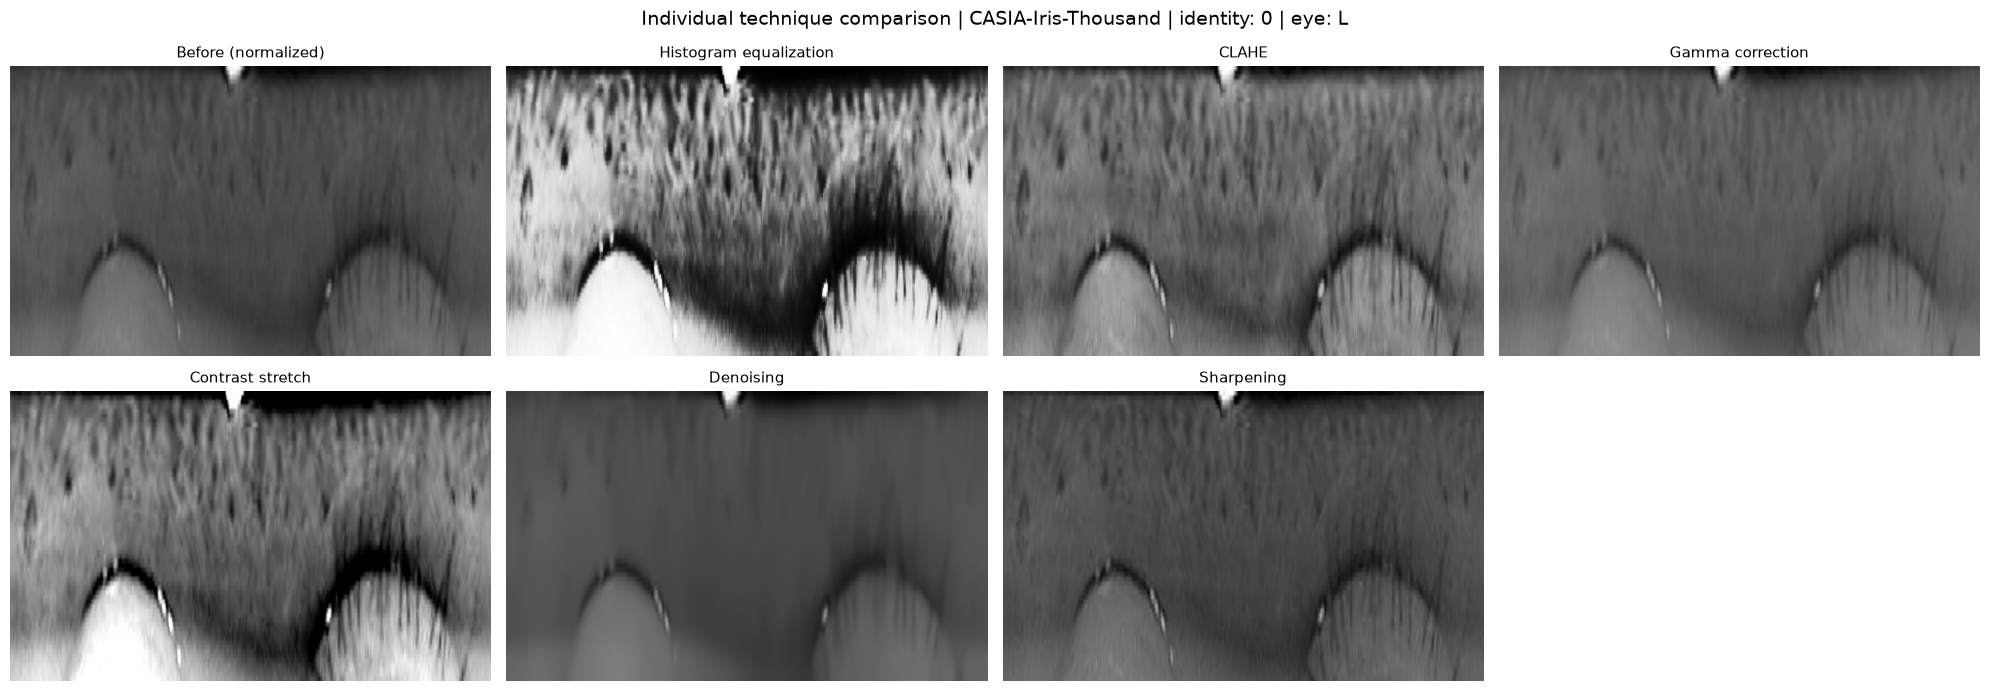

In [7]:
# ============================================================
# 8. Compare individual techniques on a sample image
# ============================================================

successful_rows = normalization_metadata[normalization_metadata["success"] == True]

if len(successful_rows) == 0:
    raise RuntimeError(
        "No successful normalizations were found in the Notebook 03 metadata. "
        "Run 03_Iris_Normalization.ipynb with a configuration that produces "
        "at least some successful normalizations before continuing."
    )

sample_row = successful_rows.iloc[0]

sample_normalized = safe_read_gray(sample_row["normalized_path"])
sample_noise_mask = safe_read_mask(sample_row["noise_mask_path"], sample_normalized.shape)
sample_valid_mask = sample_noise_mask == 0

technique_results = {
    "Before (normalized)": sample_normalized,
    "Histogram equalization": apply_histogram_equalization(sample_normalized),
    "CLAHE": apply_clahe(sample_normalized),
    "Gamma correction": apply_gamma_correction(sample_normalized),
    "Contrast stretch": apply_contrast_stretch(sample_normalized, sample_valid_mask),
    "Denoising": apply_denoising(sample_normalized),
    "Sharpening": apply_sharpening(sample_normalized),
}

fig, axes = plt.subplots(2, 4, figsize=(20, 7))
axes = axes.flatten()

for ax, (title, image) in zip(axes, technique_results.items()):
    ax.imshow(image, cmap="gray", aspect="auto")
    ax.set_title(title, fontsize=11)
    ax.axis("off")

for ax in axes[len(technique_results):]:
    ax.axis("off")

plt.suptitle(
    f"Individual technique comparison | {sample_row['dataset']} | "
    f"identity: {sample_row['identity']} | eye: {sample_row['eye']}",
    fontsize=14,
)
plt.tight_layout()
plt.show()

## 9. Final enhancement pipeline

Based on the comparison above and the rationale in Section 1, the adopted pipeline is:

```text
normalized iris texture
        |
        v
1. Denoise      (non-local means)      -- remove sensor/compression noise first
        |
        v
2. Contrast stretch  (valid-pixel percentiles) -- normalize dynamic range robustly
        |
        v
3. CLAHE        (local adaptive contrast)      -- bring out local iris texture
        |
        v
4. Sharpen      (unsharp mask)                 -- restore fine texture detail
        |
        v
enhanced iris texture
```

Global histogram equalization and a plain gamma adjustment were inspected in Section 8 but are not part of the final pipeline: global histogram equalization is more sensitive to the bright/dark outlier pixels in occluded regions than a percentile-based contrast stretch, and a fixed gamma value makes a brightness assumption that does not generalize across the two source datasets. CLAHE's local, clip-limited adaptivity is preferred for the same reason it is widely used in iris-recognition preprocessing pipelines.

`ENHANCEMENT_PIPELINE` in the configuration cell controls the exact steps and their order, so this choice can be revisited without touching the processing code below.


In [8]:
# ============================================================
# 9. Final enhancement pipeline
# ============================================================

PIPELINE_STEPS = {
    "hist_eq": lambda gray, valid_mask: apply_histogram_equalization(gray),
    "clahe": lambda gray, valid_mask: apply_clahe(gray),
    "gamma": lambda gray, valid_mask: apply_gamma_correction(gray),
    "contrast_stretch": lambda gray, valid_mask: apply_contrast_stretch(gray, valid_mask),
    "denoise": lambda gray, valid_mask: apply_denoising(gray),
    "sharpen": lambda gray, valid_mask: apply_sharpening(gray),
}


def apply_enhancement_pipeline(gray, valid_mask=None, steps=ENHANCEMENT_PIPELINE):
    '''Apply a named sequence of enhancement steps to a normalized iris texture.'''
    enhanced = gray.copy()

    for step_name in steps:
        if step_name not in PIPELINE_STEPS:
            raise ValueError(f"Unknown enhancement step: {step_name}")

        enhanced = PIPELINE_STEPS[step_name](enhanced, valid_mask)

    return enhanced

## 10. Single-image pipeline test

The full pipeline is run once on the same sample image, with a Before/After panel and an intensity histogram comparison to show the contrast change quantitatively rather than only visually.


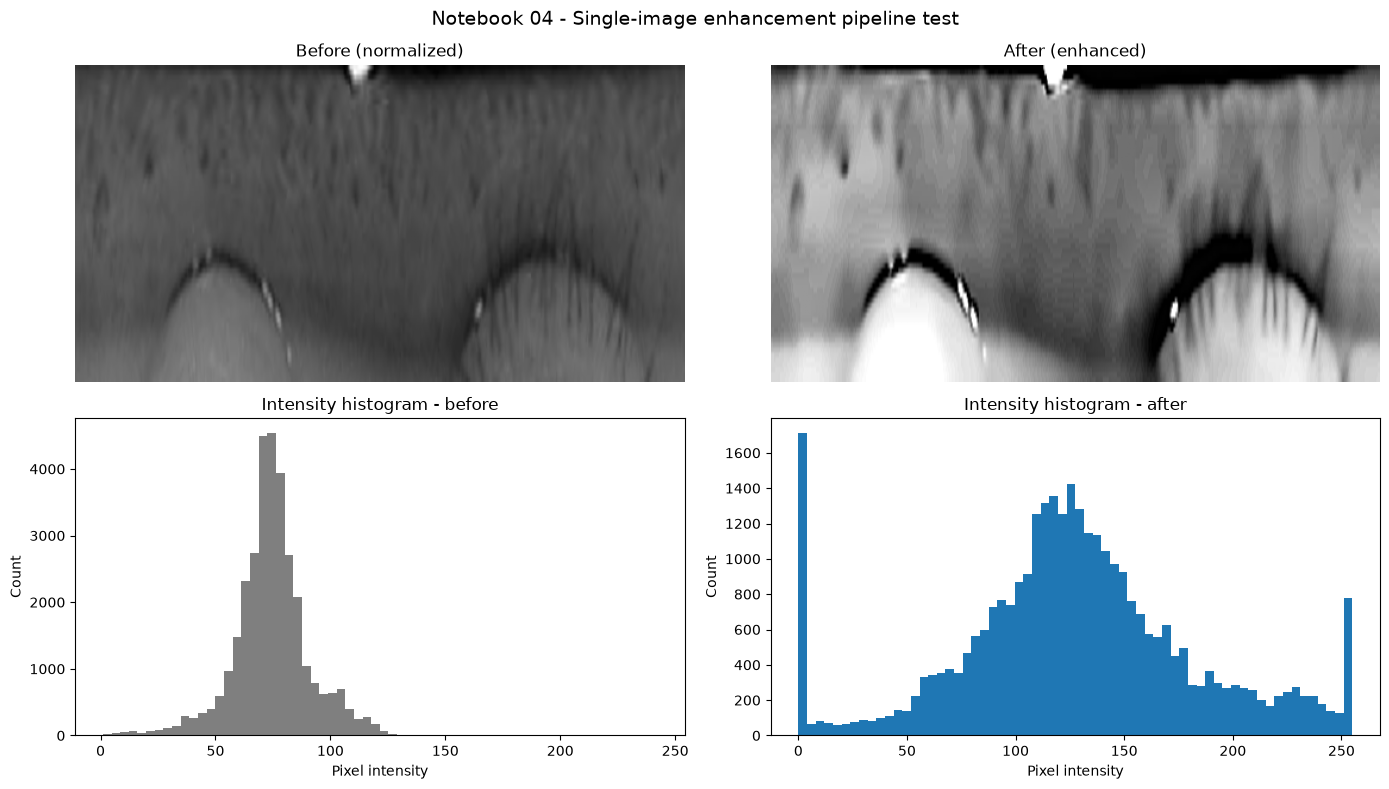

Std. dev. before: 16.93316540553058
Std. dev. after:  56.664295782344766


In [9]:
# ============================================================
# 10. Single-image pipeline test
# ============================================================

sample_enhanced = apply_enhancement_pipeline(sample_normalized, sample_valid_mask)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].imshow(sample_normalized, cmap="gray", aspect="auto")
axes[0, 0].set_title("Before (normalized)")
axes[0, 0].axis("off")

axes[0, 1].imshow(sample_enhanced, cmap="gray", aspect="auto")
axes[0, 1].set_title("After (enhanced)")
axes[0, 1].axis("off")

axes[1, 0].hist(sample_normalized.ravel(), bins=64, color="tab:gray")
axes[1, 0].set_title("Intensity histogram - before")
axes[1, 0].set_xlabel("Pixel intensity")
axes[1, 0].set_ylabel("Count")

axes[1, 1].hist(sample_enhanced.ravel(), bins=64, color="tab:blue")
axes[1, 1].set_title("Intensity histogram - after")
axes[1, 1].set_xlabel("Pixel intensity")
axes[1, 1].set_ylabel("Count")

plt.suptitle("Notebook 04 - Single-image enhancement pipeline test", fontsize=14)
plt.tight_layout()
plt.show()

print("Std. dev. before:", float(sample_normalized.std()))
print("Std. dev. after: ", float(sample_enhanced.std()))

## 11. Build output paths

Outputs are kept separate from Notebook 03. The noise mask geometry is unchanged by enhancement, so `enhancement_metadata.csv` simply carries forward the Notebook 03 `noise_mask_path` rather than duplicating the mask file.

```text
results/
└── image_enhancement/
    ├── enhanced/
    │   ├── CASIA-Iris-Thousand/
    │   └── IITD/
    ├── previews/
    └── enhancement_metadata.csv
```


In [10]:
# ============================================================
# 11. Output path helpers
# ============================================================

def dataset_safe_name(dataset):
    return (
        str(dataset)
        .replace("/", "_")
        .replace("\\\\", "_")
        .replace(" ", "_")
    )


def identity_safe_name(identity):
    if pd.isna(identity):
        return "unknown_identity"
    return str(identity).replace("/", "_").replace("\\\\", "_")


def eye_safe_name(eye):
    if pd.isna(eye):
        return "UNKNOWN"
    return str(eye).replace("/", "_")


def make_output_paths(row):
    dataset_name = dataset_safe_name(row["dataset"])
    identity_name = identity_safe_name(row["identity"])
    eye_name = eye_safe_name(row["eye"])
    stem = Path(row["filename"]).stem

    enhanced_path = (
        ENHANCED_DIR /
        dataset_name /
        identity_name /
        eye_name /
        f"{stem}_enhanced.png"
    )

    return {"enhanced_path": enhanced_path}


def ensure_parent_directories(paths):
    for path in paths.values():
        path.parent.mkdir(parents=True, exist_ok=True)

## 12. Process the datasets

Every row from Notebook 03 is carried forward, including rows that failed segmentation or normalization. Those rows are recorded with `reason = "normalization_failed"` and are not enhanced, so the full accounting from raw image to enhanced texture stays in one place.


In [11]:
# ============================================================
# 12. Select rows to process
# ============================================================

rows_to_process = []

for dataset_name, df in normalization_metadata.groupby("dataset", dropna=False):
    df = df.copy()

    if MAX_IMAGES_PER_DATASET is not None:
        df = df.sample(
            n=min(MAX_IMAGES_PER_DATASET, len(df)),
            random_state=RANDOM_SEED,
        )

    rows_to_process.append(df)

processing_metadata = pd.concat(
    rows_to_process,
    ignore_index=True,
)

print("Rows selected for enhancement stage:", len(processing_metadata))
display(processing_metadata["dataset"].value_counts())

Rows selected for enhancement stage: 22180


dataset
CASIA-Iris-Thousand    20000
IITD                    2180
Name: count, dtype: int64

In [12]:
# ============================================================
# 13. Run enhancement and save outputs
# ============================================================

records = []

total = len(processing_metadata)

for idx, row in processing_metadata.iterrows():

    record = {
        "dataset": row["dataset"],
        "identity": row["identity"],
        "eye": row["eye"],
        "filename": row["filename"],
        "normalized_path": row.get("normalized_path"),
        "noise_mask_path": row.get("noise_mask_path"),
        "valid_fraction": row.get("valid_fraction"),
        "success": False,
        "reason": None,
        "enhancement_pipeline": " -> ".join(ENHANCEMENT_PIPELINE),
        "mean_intensity_before": np.nan,
        "std_intensity_before": np.nan,
        "mean_intensity_after": np.nan,
        "std_intensity_after": np.nan,
        "enhanced_path": None,
    }

    if not bool(row["success"]):
        record["reason"] = "normalization_failed"
        records.append(record)
        continue

    try:
        normalized = safe_read_gray(row["normalized_path"])
        noise_mask = safe_read_mask(row["noise_mask_path"], normalized.shape)
        valid_mask = noise_mask == 0

        enhanced = apply_enhancement_pipeline(normalized, valid_mask)

        output_paths = make_output_paths(row)
        ensure_parent_directories(output_paths)

        cv2.imwrite(
            str(output_paths["enhanced_path"]),
            enhanced,
        )

        record["success"] = True
        record["mean_intensity_before"] = float(normalized.mean())
        record["std_intensity_before"] = float(normalized.std())
        record["mean_intensity_after"] = float(enhanced.mean())
        record["std_intensity_after"] = float(enhanced.std())
        record["enhanced_path"] = str(output_paths["enhanced_path"])

    except Exception as e:
        record["success"] = False
        record["reason"] = f"exception: {e}"

    records.append(record)

    if (idx + 1) % 200 == 0 or (idx + 1) == total:
        print(f"Processed {idx + 1} / {total} images")

enhancement_metadata = pd.DataFrame(records)

print("\\nEnhancement complete.")
print("Successful enhancements:", int(enhancement_metadata["success"].sum()), "/", len(enhancement_metadata))

Processed 200 / 22180 images
Processed 400 / 22180 images
Processed 600 / 22180 images
Processed 800 / 22180 images
Processed 1000 / 22180 images
Processed 1200 / 22180 images
Processed 1400 / 22180 images
Processed 1600 / 22180 images
Processed 1800 / 22180 images
Processed 2000 / 22180 images
Processed 2200 / 22180 images
Processed 2400 / 22180 images
Processed 2600 / 22180 images
Processed 2800 / 22180 images
Processed 3000 / 22180 images
Processed 3200 / 22180 images
Processed 3400 / 22180 images
Processed 3600 / 22180 images
Processed 3800 / 22180 images
Processed 4000 / 22180 images
Processed 4200 / 22180 images
Processed 4400 / 22180 images
Processed 4600 / 22180 images
Processed 4800 / 22180 images
Processed 5000 / 22180 images
Processed 5200 / 22180 images
Processed 5400 / 22180 images
Processed 5600 / 22180 images
Processed 5800 / 22180 images
Processed 6000 / 22180 images
Processed 6200 / 22180 images
Processed 6400 / 22180 images
Processed 6600 / 22180 images
Processed 6800

## 14. Save enhancement metadata

The requested hand-off file for Notebook 05 is `enhancement_metadata.csv`, saved inside `results/image_enhancement/`.


In [13]:
# ============================================================
# 14. Save enhancement metadata
# ============================================================

ENHANCEMENT_METADATA_PATH = RESULTS_DIR / "enhancement_metadata.csv"

enhancement_metadata.to_csv(
    ENHANCEMENT_METADATA_PATH,
    index=False,
)

print("Saved:", ENHANCEMENT_METADATA_PATH)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\image_enhancement\enhancement_metadata.csv


## 15. Enhancement statistics

These statistics are diagnostic. A rise in standard deviation after enhancement is an expected, simple signal that local contrast increased; it is not a substitute for the dedicated quality assessment performed in Notebook 05.


In [14]:
# ============================================================
# 15. Enhancement statistics
# ============================================================

total_images = len(enhancement_metadata)
successful = int(enhancement_metadata["success"].sum())

summary = {
    "total_images": total_images,
    "successful_enhancements": successful,
    "failed_enhancements": total_images - successful,
    "success_rate_percent": (
        100 * successful / total_images
        if total_images else 0.0
    ),
    "mean_std_intensity_before": (
        enhancement_metadata.loc[
            enhancement_metadata["success"], "std_intensity_before"
        ].mean()
    ),
    "mean_std_intensity_after": (
        enhancement_metadata.loc[
            enhancement_metadata["success"], "std_intensity_after"
        ].mean()
    ),
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["metric", "value"],
)

display(summary_df)

print("\\nFailure reasons:")
display(
    enhancement_metadata.loc[
        ~enhancement_metadata["success"],
        "reason"
    ].value_counts(dropna=False)
)

,metric,value
0,total_images,22180.000000
1,successful_enhancements,22176.000000
2,failed_enhancements,4.000000
3,success_rate_percent,99.981966
4,mean_std_intensity_before,24.610969
5,mean_std_intensity_after,64.064368


\nFailure reasons:


reason
normalization_failed    4
Name: count, dtype: int64

## 16. Dataset-wise enhancement summary

In [15]:
# ============================================================
# 16. Dataset-wise enhancement summary
# ============================================================

dataset_enhancement_summary = (
    enhancement_metadata
    .groupby("dataset")
    .agg(
        total_images=("filename", "count"),
        successful=("success", "sum"),
        mean_std_before=("std_intensity_before", "mean"),
        mean_std_after=("std_intensity_after", "mean"),
    )
    .reset_index()
)

dataset_enhancement_summary["success_rate_percent"] = (
    100 *
    dataset_enhancement_summary["successful"] /
    dataset_enhancement_summary["total_images"]
)

display(dataset_enhancement_summary)

dataset_summary_path = RESULTS_DIR / "enhancement_summary_by_dataset.csv"

dataset_enhancement_summary.to_csv(
    dataset_summary_path,
    index=False,
)

print("Saved:", dataset_summary_path)

,dataset,total_images,successful,mean_std_before,mean_std_after,success_rate_percent
0,CASIA-Iris-Thousand,20000,20000,23.308234,63.182958,100.000000
1,IITD,2180,2176,36.584637,72.165558,99.816514


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\image_enhancement\enhancement_summary_by_dataset.csv


## 17. Visual quality-control previews: Before vs After

The following previews display, for a sample of successfully enhanced images per dataset:

1. the normalized texture before enhancement,
2. the enhanced texture after the full pipeline,
3. the intensity histogram before,
4. the intensity histogram after.

The previews are saved to `results/image_enhancement/previews/`.


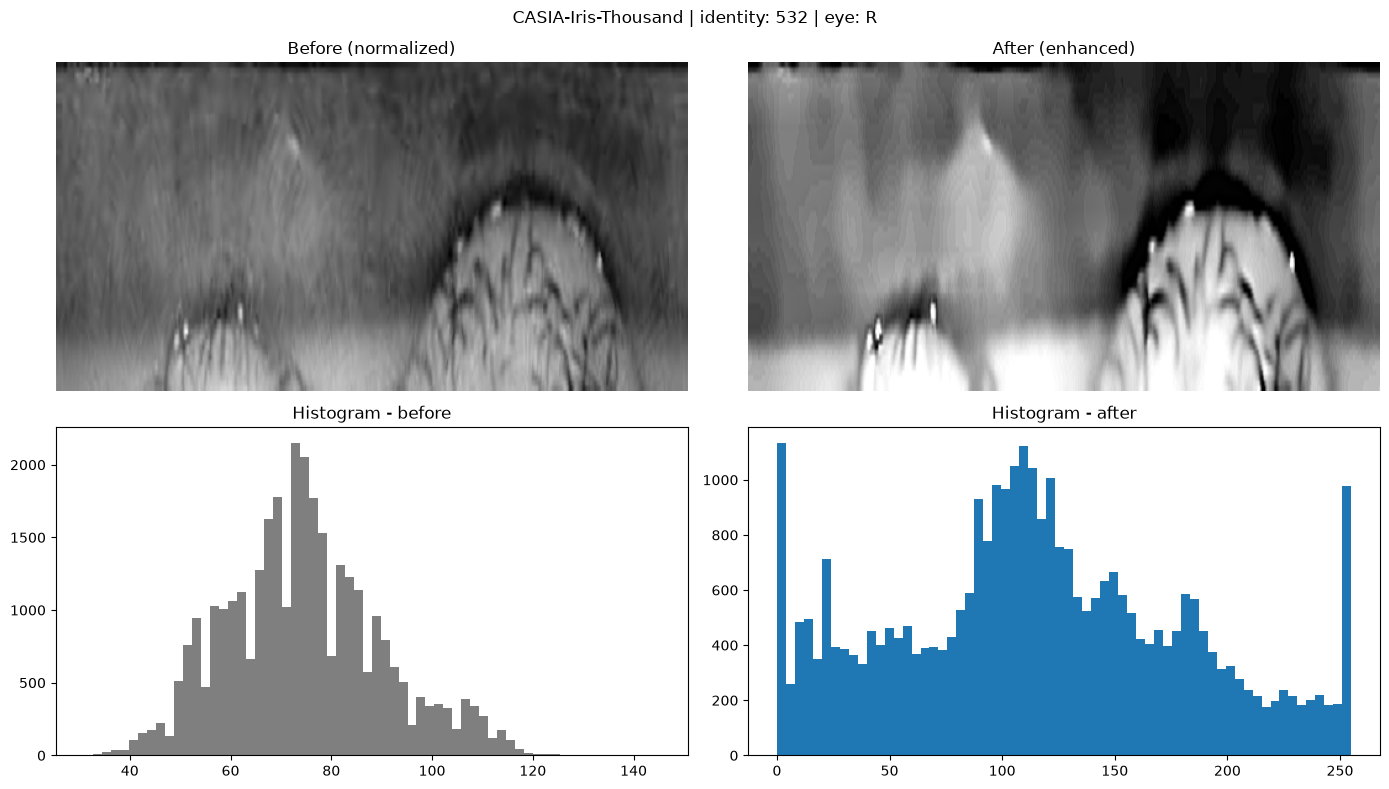

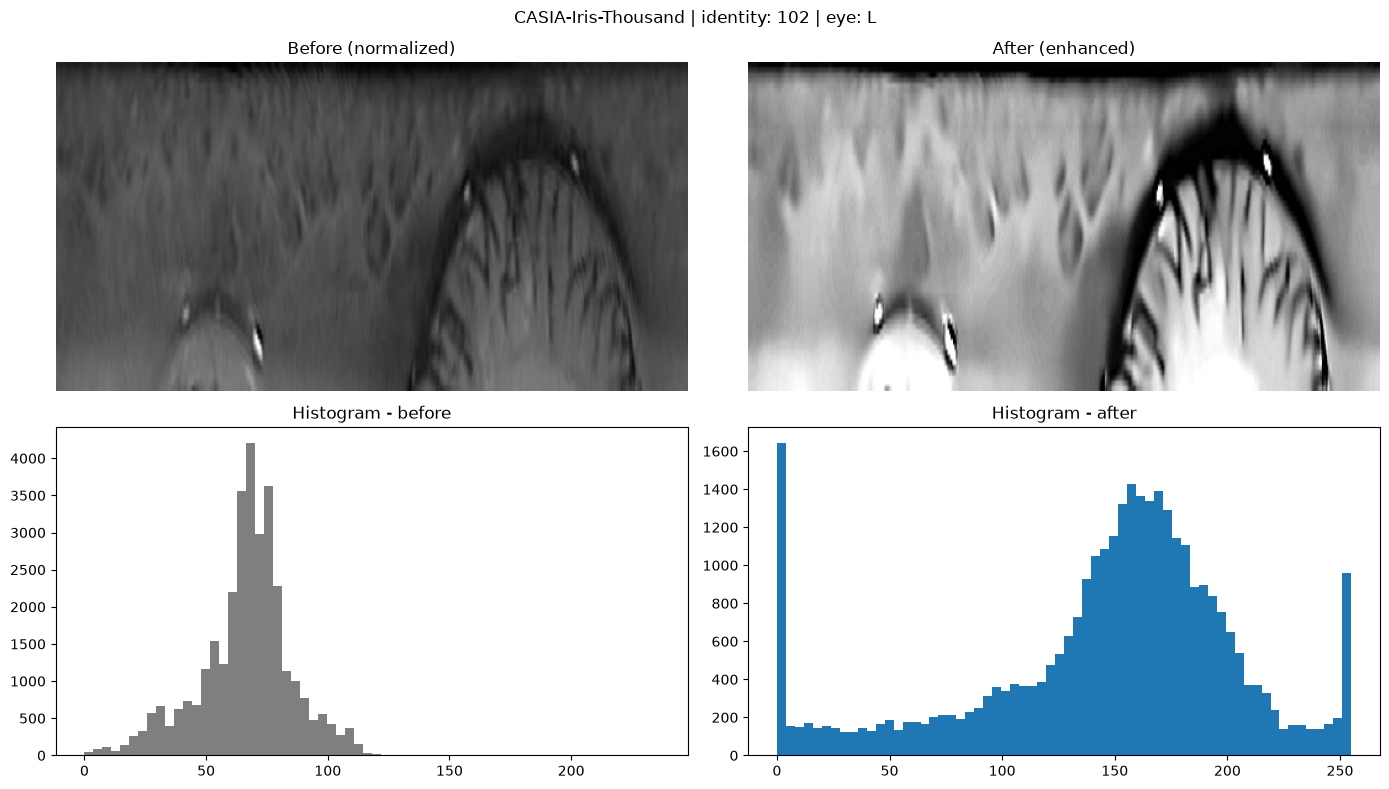

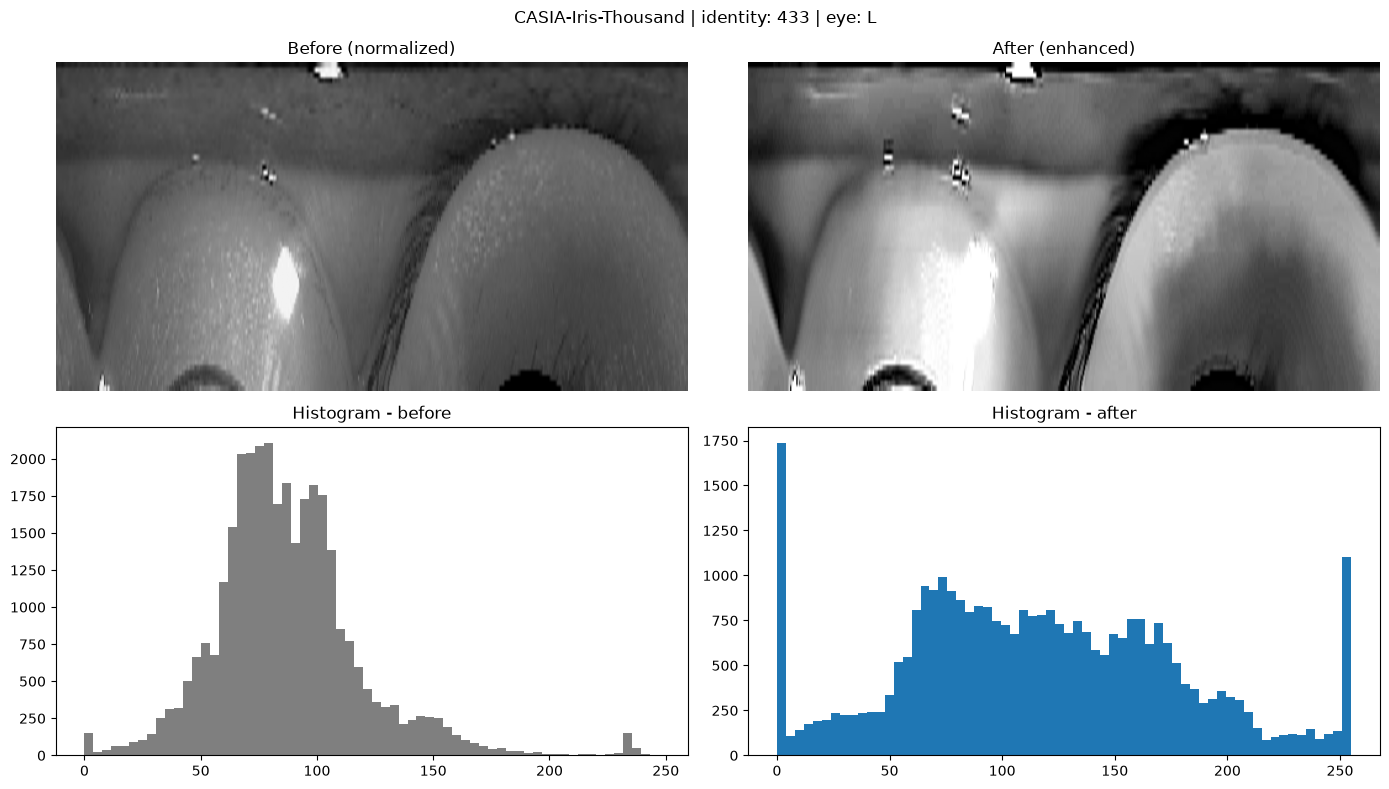

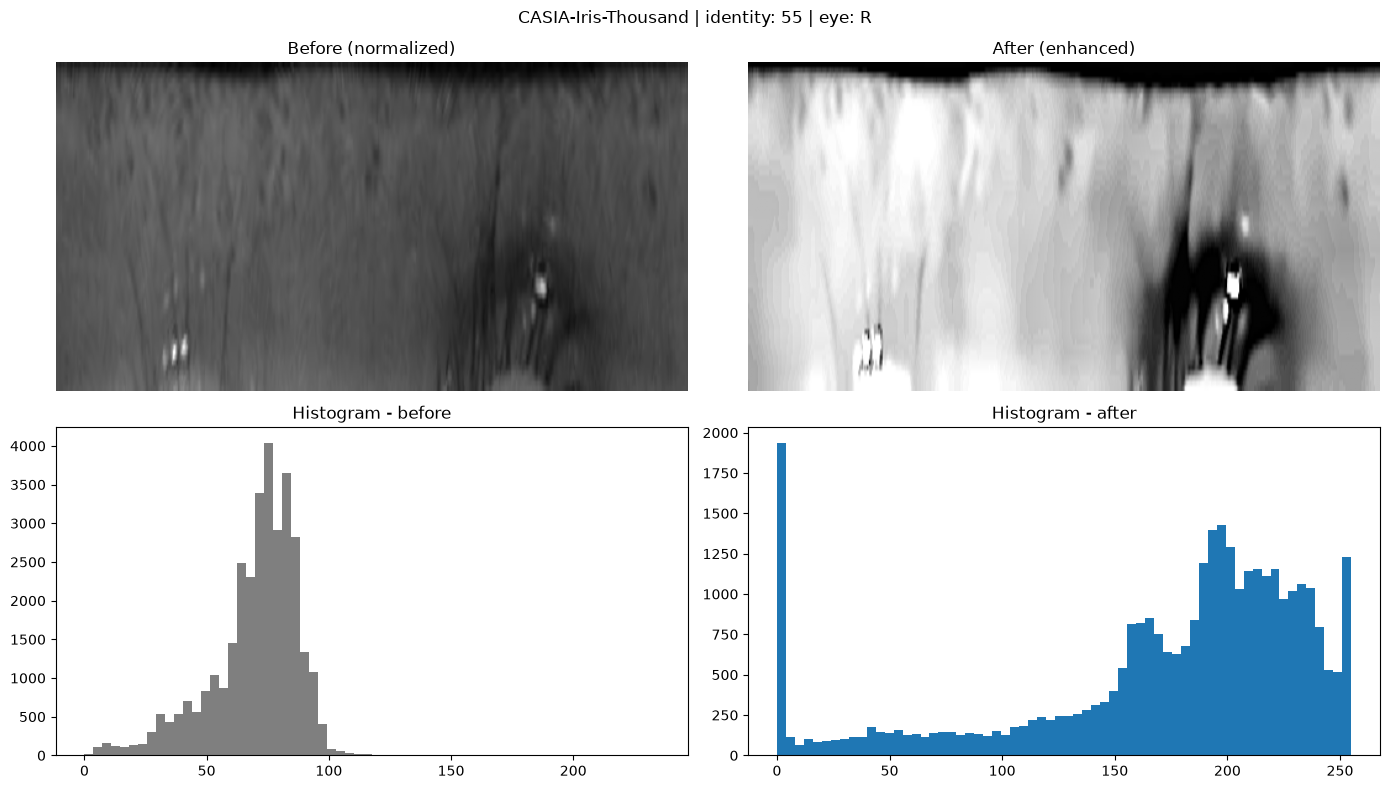

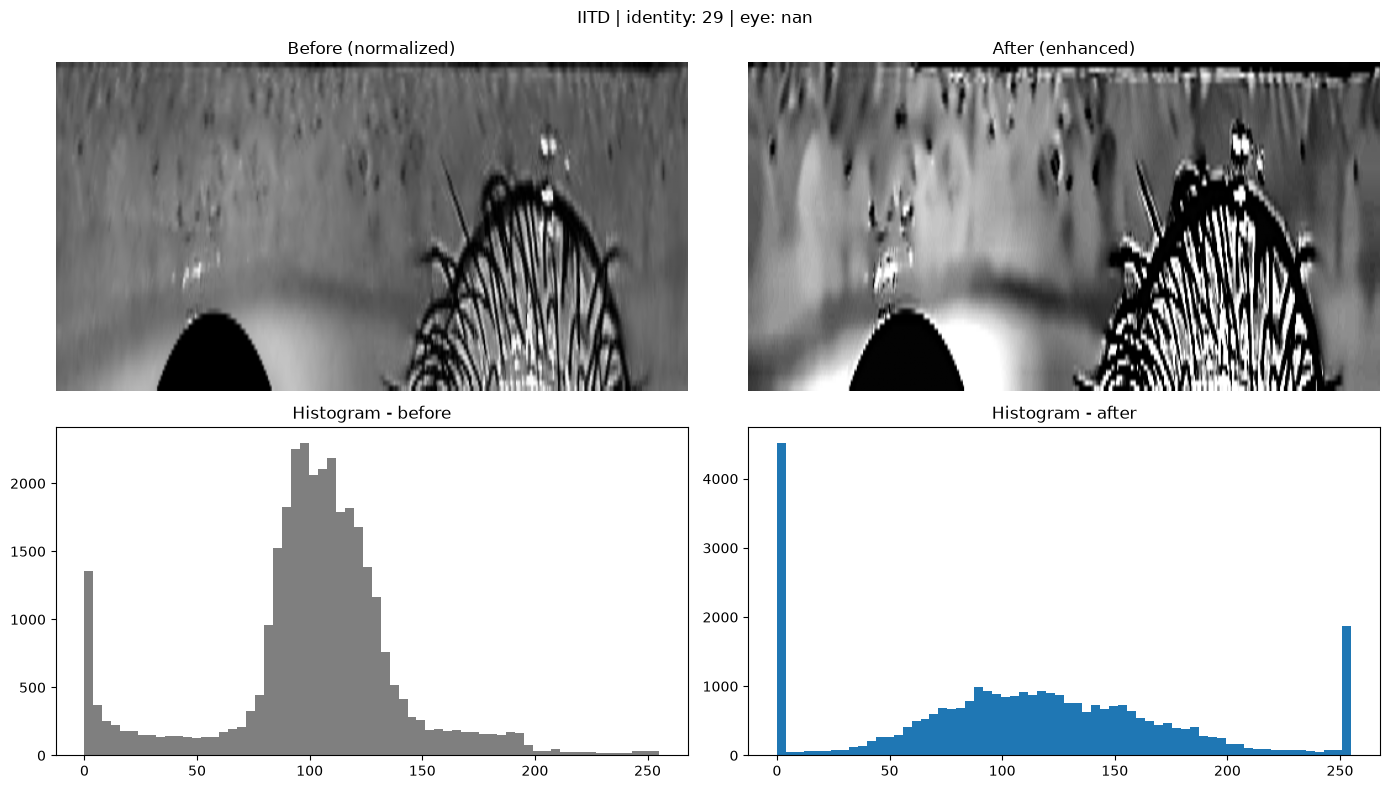

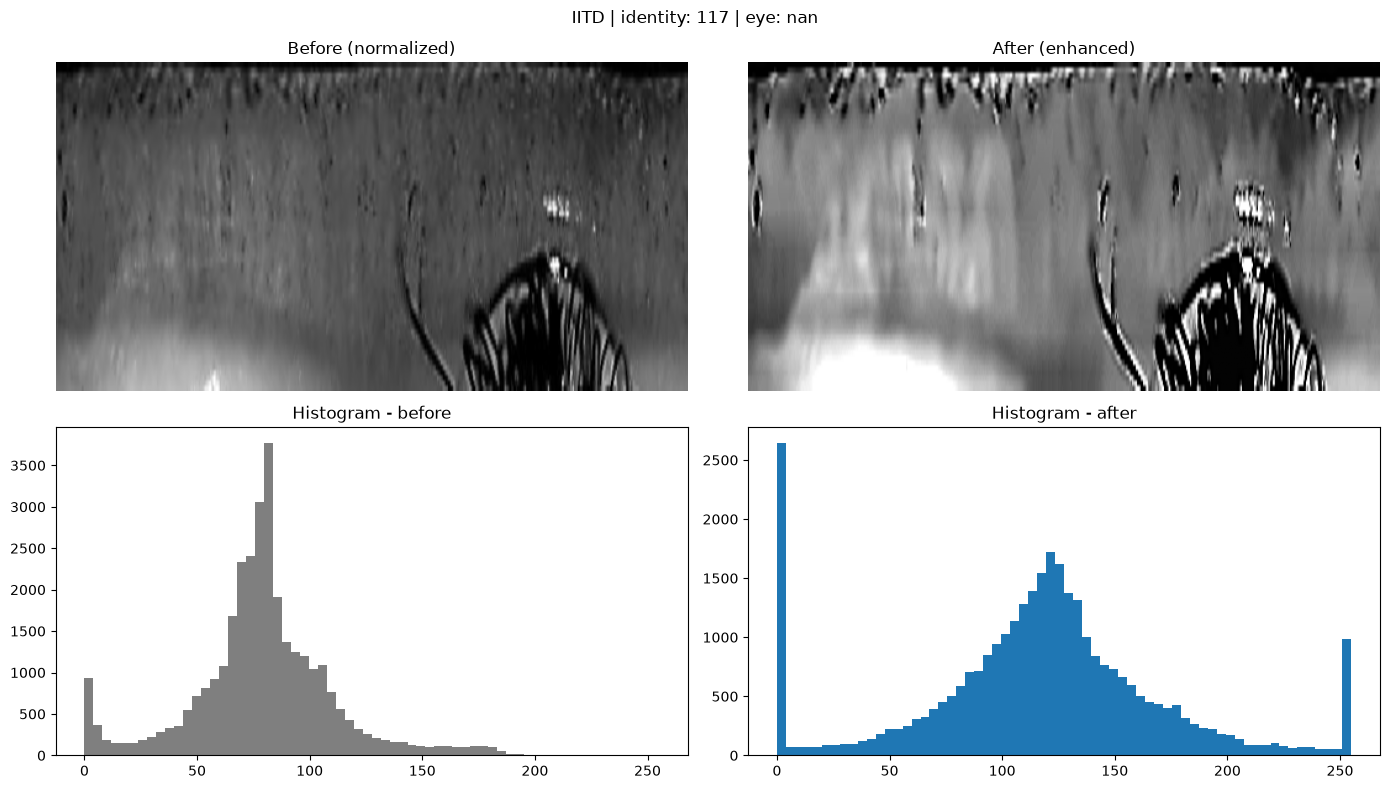

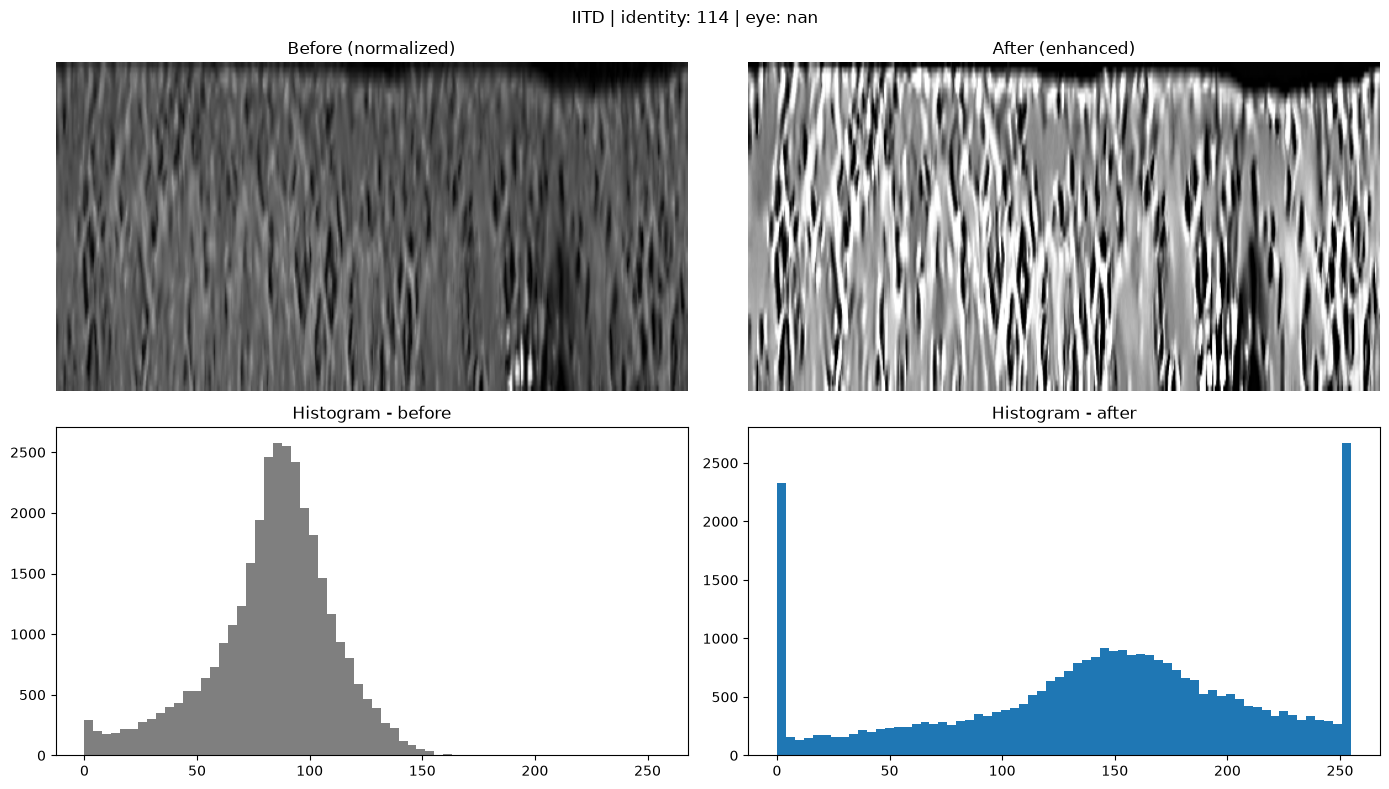

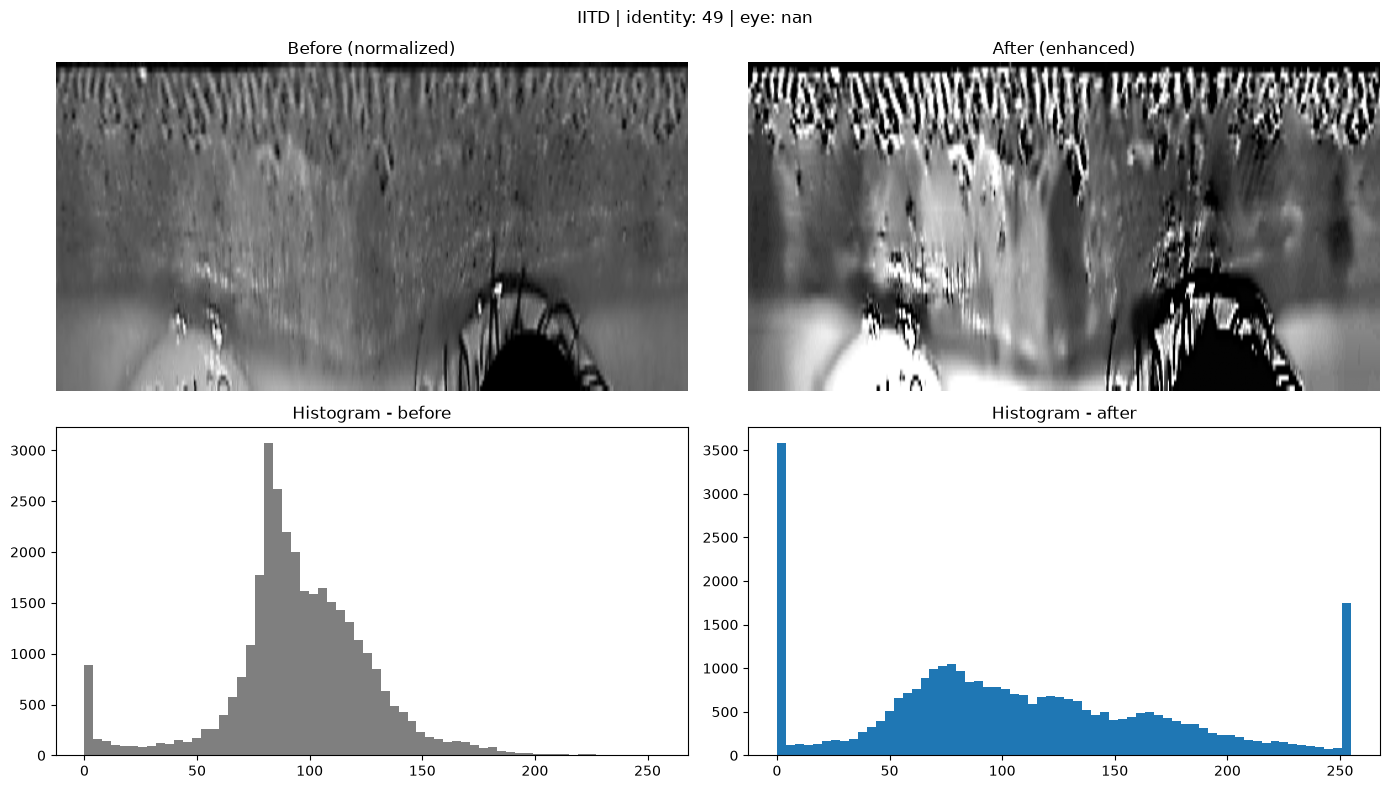

In [16]:
# ============================================================
# 17. Save representative Before vs After previews
# ============================================================

def create_preview(row):
    normalized = cv2.imread(str(row["normalized_path"]), cv2.IMREAD_GRAYSCALE)
    enhanced = cv2.imread(str(row["enhanced_path"]), cv2.IMREAD_GRAYSCALE)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    axes[0, 0].imshow(normalized, cmap="gray", aspect="auto")
    axes[0, 0].set_title("Before (normalized)")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(enhanced, cmap="gray", aspect="auto")
    axes[0, 1].set_title("After (enhanced)")
    axes[0, 1].axis("off")

    axes[1, 0].hist(normalized.ravel(), bins=64, color="tab:gray")
    axes[1, 0].set_title("Histogram - before")

    axes[1, 1].hist(enhanced.ravel(), bins=64, color="tab:blue")
    axes[1, 1].set_title("Histogram - after")

    plt.suptitle(
        f"{row['dataset']} | identity: {row['identity']} | eye: {row['eye']}",
        fontsize=12,
    )
    plt.tight_layout()

    output_path = (
        PREVIEW_DIR /
        f"{dataset_safe_name(row['dataset'])}_{Path(row['filename']).stem}_before_after.png"
    )

    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()

    return output_path


if SAVE_PREVIEWS:
    for dataset_name, df in enhancement_metadata.groupby("dataset"):

        successful_df = df[df["success"] == True]

        if len(successful_df) == 0:
            print(f"No successful enhancements to preview for {dataset_name}")
            continue

        preview_sample = successful_df.sample(
            n=min(PREVIEW_COUNT_PER_DATASET, len(successful_df)),
            random_state=RANDOM_SEED,
        )

        # Preview generation can be slow for large samples; limit to a
        # small number of inline plots and rely on the saved PNGs for
        # the remainder.
        for _, row in preview_sample.head(4).iterrows():
            create_preview(row)

## 18. Failure review table

Images that fail enhancement (including those that already failed segmentation or normalization) are retained in the metadata rather than silently discarded, for the same reason given in Notebooks 02 and 03.


In [17]:
# ============================================================
# 18. Failure review
# ============================================================

failure_table = enhancement_metadata[
    ~enhancement_metadata["success"]
].copy()

display(
    failure_table[
        [
            "dataset",
            "identity",
            "eye",
            "filename",
            "reason",
        ]
    ].head(50)
)

FAILURE_REPORT_PATH = RESULTS_DIR / "enhancement_failures.csv"

failure_table.to_csv(
    FAILURE_REPORT_PATH,
    index=False,
)

print("Saved:", FAILURE_REPORT_PATH)

,dataset,identity,eye,filename,reason
21747,IITD,175,NaN,08_R.bmp,normalization_failed
22010,IITD,202,NaN,01_L.bmp,normalization_failed
22011,IITD,202,NaN,02_L.bmp,normalization_failed
22014,IITD,202,NaN,05_L.bmp,normalization_failed


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\image_enhancement\enhancement_failures.csv


## 19. Contrast improvement distribution

The ratio of standard deviation after enhancement to standard deviation before enhancement is a simple, diagnostic proxy for local contrast gain. Values far above 1 concentrated in a few images may indicate the pipeline is amplifying noise rather than genuine texture, and are worth spot-checking against the saved previews. This is diagnostic only; final quality-based filtering belongs to Notebook 05.


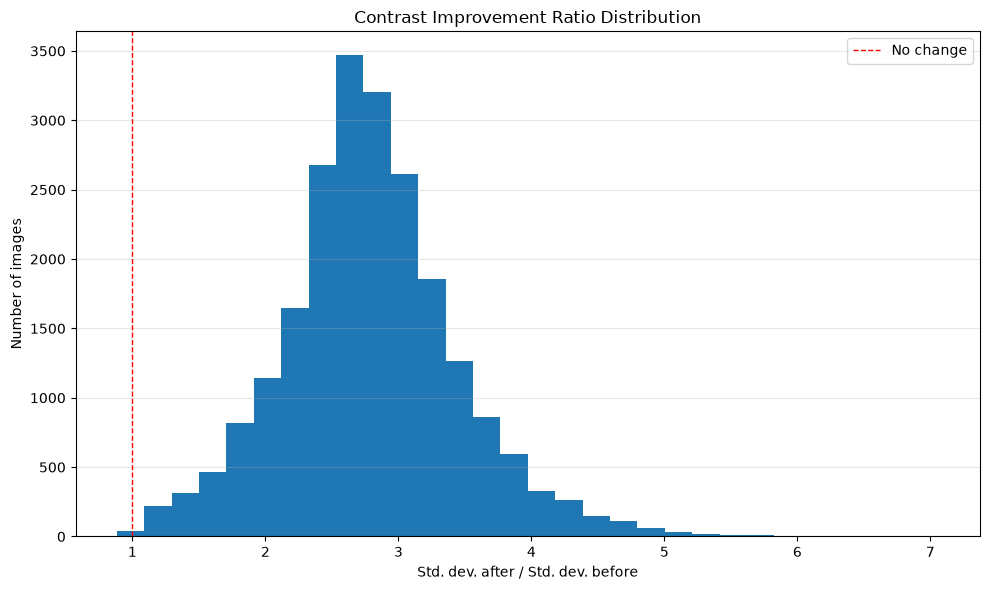

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\image_enhancement\contrast_improvement_distribution.png


In [18]:
# ============================================================
# 19. Plot contrast improvement ratio
# ============================================================

successful_enh = enhancement_metadata[enhancement_metadata["success"] == True].copy()

successful_enh["contrast_ratio"] = (
    successful_enh["std_intensity_after"] /
    successful_enh["std_intensity_before"].replace(0, np.nan)
)

plt.figure(figsize=(10, 6))

if len(successful_enh):
    plt.hist(
        successful_enh["contrast_ratio"].dropna(),
        bins=30,
    )

plt.xlabel("Std. dev. after / Std. dev. before")
plt.ylabel("Number of images")
plt.title("Contrast Improvement Ratio Distribution")
plt.axvline(1.0, color="red", linestyle="--", linewidth=1, label="No change")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

contrast_plot_path = RESULTS_DIR / "contrast_improvement_distribution.png"

plt.savefig(
    contrast_plot_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", contrast_plot_path)

## 20. Check enhancement output files

Verify that every successfully enhanced image has an output file on disk, and that the referenced Notebook 03 noise mask is still reachable.


In [19]:
# ============================================================
# 20. Output verification
# ============================================================

def path_exists(path_value):
    '''Safely check whether a stored file path exists.'''

    if pd.isna(path_value):
        return False

    if not isinstance(path_value, (str, Path)):
        return False

    if isinstance(path_value, str) and not path_value.strip():
        return False

    return Path(path_value).exists()


verification_rows = []

for _, row in enhancement_metadata.iterrows():

    checks = {
        "enhanced_exists": path_exists(row["enhanced_path"]),
        "noise_mask_exists": path_exists(row["noise_mask_path"]),
    }

    verification_rows.append(checks)


verification_df = pd.DataFrame(verification_rows)

display(
    verification_df.mean()
    .rename("completion_rate")
    .to_frame()
)

,completion_rate
enhanced_exists,0.99982
noise_mask_exists,0.99982


## 21. Final outputs

At the end of Notebook 04, the project should contain:

```text
results/image_enhancement/
├── enhanced/
├── previews/
├── enhancement_metadata.csv
├── enhancement_summary_by_dataset.csv
├── enhancement_failures.csv
└── contrast_improvement_distribution.png
```

### Main hand-off file

`enhancement_metadata.csv` is the critical output for later notebooks. It tells later stages exactly which normalized texture produced which enhanced texture, which pipeline was used, and points back to the unchanged Notebook 03 `noise_mask_path` for excluding unreliable pixels.


In [20]:
# ============================================================
# 21. Final output verification
# ============================================================

print("Notebook 04 output directory:")
print(RESULTS_DIR)

print("\\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print("\\nEnhancement success rate:")
print(
    f"{enhancement_metadata['success'].mean() * 100:.2f}%"
    if len(enhancement_metadata)
    else "N/A"
)

print("\\nNotebook 04 completed.")

Notebook 04 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\image_enhancement
\nTop-level generated files:
- contrast_improvement_distribution.png
- enhancement_failures.csv
- enhancement_metadata.csv
- enhancement_summary_by_dataset.csv
\nEnhancement success rate:
99.98%
\nNotebook 04 completed.


## 22. What this notebook hands to Notebook 05

Notebook 05 performs **iris quality assessment** on the enhanced textures produced here.

The expected hand-off is:

```text
Notebook 02             Notebook 03                Notebook 04
Segmented iris    --->  Rubber-sheet         --->  Enhanced iris texture
+ masks                 normalization              (CLAHE / denoise /
+ boundaries             + noise mask               contrast stretch /
                                                       sharpen)
                                                              |
                                                              v
                                                  Notebook 05
                                                  Iris quality assessment
```

Notebook 04 must therefore remain independent of quality scoring: the enhanced images saved here are photometrically improved but not yet judged for usability, so that Notebook 05 has a consistent, already-enhanced starting point for every image, including the ones that will ultimately be filtered out.

### Important research rule

Do not compute quality scores, sharpness/focus metrics, or accept/reject decisions in this notebook. Those steps belong to Notebook 05 and should be applied to the `enhanced_path` images referenced in `enhancement_metadata.csv`, using `noise_mask_path` to exclude occluded pixels from any quality statistic.
